In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
from shapely.geometry import Point 
from matplotlib import pyplot as plt

# Spatial Aggregation

In [6]:
# load Naturraeume Brandenburg
NATRAUM = gpd.read_file("../data/brandenburg_shape/naturraum_scholz_ohne_Berlin_regionid.gpkg", layer="natraum_scholz_ohneBerlin_regionid")

In [7]:
print(NATRAUM.crs)
print(NATRAUM.geom_type.value_counts().to_dict())
print(len(NATRAUM))
print(NATRAUM.total_bounds)
print(NATRAUM.columns)

EPSG:4326
{'MultiPolygon': 79}
79
[11.26601236 51.35826207 14.76432439 53.55806679]
Index(['AREA', 'NR_HAUPT', 'NAME_HAUPT', 'NR_UNTER', 'NAME_UNTER', 'FLäCHE',
       'region_id', 'geometry'],
      dtype='str')


In [8]:
NATRAUM["NR_UNTER"].nunique()

75

In [9]:
natraum_3035 = NATRAUM.to_crs("EPSG:3035")

In [10]:
# load pr and sm as example
pr = xr.open_dataset(Path("../data/imported/hyras_pr_v6-1_2001_2025.nc"))
pr_da = pr["pr"]

sm = xr.open_dataset(Path("../data/imported/grids_germany_daily_soil_moisture_composite_0-10_v1.nc"))
sm_da = sm["sm_dwd_0_10"]

In [ ]:
# add unique identifier to natraum // added in QGIS and natraum geloaded
#natraum_3035["region_id"] = range(len(natraum_3035))
#natraum_3035.columns

Index(['AREA', 'PERIMETER', 'NR_HAUPT', 'NAME_HAUPT', 'NR_UNTER', 'NAME_UNTER',
       'FLäCHE', 'geometry', 'region_id'],
      dtype='str')

In [11]:
# make a grid cell centre look up table 
x, y = np.meshgrid(pr_da.x.values, pr_da.y.values)

grid_points_hyras = gpd.GeoDataFrame(
    {
        "x": x.ravel(),
        "y": y.ravel()
    },
    geometry=[
        Point(xi, yi)
        for xi, yi in zip(x.ravel(), y.ravel())
    ],
    crs="EPSG:3035",
)

In [12]:
# join the grid cells to natraum 
grid_natraum_hyras = gpd.sjoin(
    grid_points_hyras,
    natraum_3035[
        [
            "region_id",
            "NR_HAUPT",
            "NAME_HAUPT",
            "NR_UNTER",
            "NAME_UNTER",
            "AREA",
            "geometry",
        ]
    ],
    how="left",
    predicate="within",
)

In [13]:
print(grid_natraum_hyras["NR_UNTER"].isna().sum())
print(grid_natraum_hyras["NR_UNTER"].sum())
print(grid_natraum_hyras.shape)

40565
23885628.0
(70225, 10)


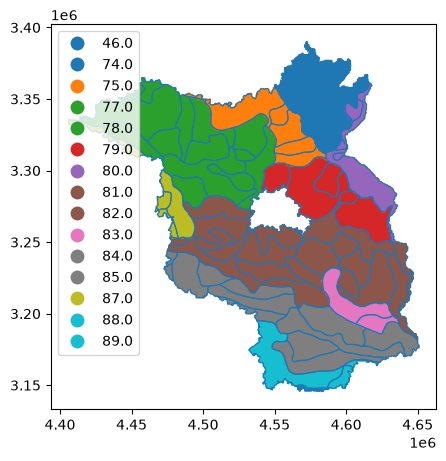

In [14]:
fig, ax = plt.subplots(figsize=(5, 5))

natraum_3035.boundary.plot(
    ax=ax,
    linewidth=0.8
)

grid_natraum_hyras.plot(
    ax=ax,
    column="NR_HAUPT",
    categorical=True,
    legend=True,
    markersize=1
)

plt.show()

In [15]:
grid_natraum_hyras[grid_natraum_hyras["region_id"].notnull()].head(3)
print(grid_natraum_hyras["region_id"].nunique())

79


In [16]:
# reshape to 2D array
region_ids = grid_natraum_hyras["region_id"].to_numpy().reshape(len(pr_da.y), len(pr_da.x))
region_ids

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(265, 265))

In [17]:
region_id_da = xr.DataArray(region_ids, dims=("y", "x"), coords={"y": pr["y"], "x": pr["x"]}, name="region_id")
region_id_da 

<xarray.DataArray 'region_id' (y: 265, x: 265)> Size: 562kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(265, 265))
Coordinates:
  * y        (y) float64 2kB 3.136e+06 3.136e+06 3.138e+06 ... 3.398e+06 3.4e+06
  * x        (x) float64 2kB 4.396e+06 4.398e+06 4.398e+06 ... 4.66e+06 4.66e+06

In [18]:
# test pr aggregation by region_id
pr_region_daily = pr_da.groupby(region_id_da).mean(dim="stacked_y_x")
pr_region_daily

<xarray.DataArray 'pr' (time: 9131, region_id: 79)> Size: 3MB
array([[2.0617368e+00, 3.4216485e+00, 2.2074385e+00, ..., 1.6131580e+00,
        1.4466157e+00, 1.2441863e+00],
       [9.5276761e-01, 1.0123713e+00, 4.1157025e-01, ..., 2.1052634e-02,
        9.7744420e-02, 1.4418603e-01],
       [4.1020569e-01, 2.2371128e-01, 3.4297466e-01, ..., 9.0789473e-01,
        7.3383486e-01, 3.4883726e-02],
       ...,
       [3.0772558e-01, 5.0515439e-02, 4.3305787e-01, ..., 7.3421049e-01,
        1.7654136e+00, 2.2046521e+00],
       [2.2614419e-01, 5.5670083e-02, 2.5950420e-01, ..., 0.0000000e+00,
        0.0000000e+00, 4.6511628e-03],
       [1.8258061e+00, 1.9422685e+00, 1.7223141e+00, ..., 4.6105266e+00,
        5.6270666e+00, 4.3906980e+00]], shape=(9131, 79), dtype=float32)
Coordinates:
  * time       (time) datetime64[ns] 73kB 2001-01-01 2001-01-02 ... 2025-12-31
  * region_id  (region_id) float64 632B 1.0 2.0 3.0 4.0 ... 76.0 77.0 78.0 79.0
Attributes:
    standard_name:      thickness_of_rainfall_amount
    long_name:          Daily Precipitation Sum
    units:              mm
    CoordinateSystems:  LatLonCoordinateSystem ProjectionCoordinateSystem
    esri_pe_string:     PROJCS["ETRS_1989_LAEA",GEOGCS["GCS_ETRS_1989",DATUM[...
    grid_mapping:       crs
    cell_methods:       time: sum

In [19]:
pr_region_daily.region_id

<xarray.DataArray 'region_id' (region_id: 79)> Size: 632B
array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13., 14.,
       15., 16., 17., 18., 19., 20., 21., 22., 23., 24., 25., 26., 27., 28.,
       29., 30., 31., 32., 33., 34., 35., 36., 37., 38., 39., 40., 41., 42.,
       43., 44., 45., 46., 47., 48., 49., 50., 51., 52., 53., 54., 55., 56.,
       57., 58., 59., 60., 61., 62., 63., 64., 65., 66., 67., 68., 69., 70.,
       71., 72., 73., 74., 75., 76., 77., 78., 79.])
Coordinates:
  * region_id  (region_id) float64 632B 1.0 2.0 3.0 4.0 ... 76.0 77.0 78.0 79.0

In [20]:
pr_region_daily.shape

(9131, 79)

In [21]:
## look up table for dwd sm grid (cause of different EPSG)
x, y = np.meshgrid(sm_da.x.values, sm_da.y.values)
grid_points_sm = gpd.GeoDataFrame(
    {
        "x": x.ravel(),
        "y": y.ravel(),
    },
    geometry=[
        Point(xi, yi)
        for xi, yi in zip(x.ravel(), y.ravel())
    ],
    crs="EPSG:31467",
)

In [22]:
natraum_31467 = natraum_3035.to_crs("EPSG:31467")

In [23]:
# spatial join
grid_natraum_sm = gpd.sjoin(
    grid_points_sm,
    natraum_31467[
        ["region_id",
         "NR_HAUPT",
         "NAME_HAUPT",
         "NR_UNTER",
         "NAME_UNTER",
         "AREA",
         "geometry"
        ]
    ],
    how="left",
    predicate="within"
)

In [24]:
print(grid_natraum_sm.shape)
print(grid_natraum_sm["region_id"].nunique())
print(grid_natraum_sm["region_id"].isna().sum())

(72630, 10)
79
42918


In [25]:
# export both look up tables for preprocessing function
grid_natraum_hyras.to_parquet("../data/processed/cell_centers_grid_naturraum_for_hyras.parquet")
grid_natraum_sm.to_parquet("../data/processed/cell_centers_grid_naturraum_for_sm.parquet")

In [26]:
# check if I can load exportet parquet files
test_hyras = gpd.read_parquet("../data/processed/cell_centers_grid_naturraum_for_hyras.parquet")
test_sm = gpd.read_parquet("../data/processed/cell_centers_grid_naturraum_for_sm.parquet")

In [27]:
print(test_hyras)
print(test_sm)

               x          y                 geometry  index_right  region_id  \
0      4396500.0  3135500.0  POINT (4396500 3135500)          NaN        NaN   
1      4397500.0  3135500.0  POINT (4397500 3135500)          NaN        NaN   
2      4398500.0  3135500.0  POINT (4398500 3135500)          NaN        NaN   
3      4399500.0  3135500.0  POINT (4399500 3135500)          NaN        NaN   
4      4400500.0  3135500.0  POINT (4400500 3135500)          NaN        NaN   
...          ...        ...                      ...          ...        ...   
70220  4656500.0  3399500.0  POINT (4656500 3399500)          NaN        NaN   
70221  4657500.0  3399500.0  POINT (4657500 3399500)          NaN        NaN   
70222  4658500.0  3399500.0  POINT (4658500 3399500)          NaN        NaN   
70223  4659500.0  3399500.0  POINT (4659500 3399500)          NaN        NaN   
70224  4660500.0  3399500.0  POINT (4660500 3399500)          NaN        NaN   

       NR_HAUPT NAME_HAUPT  NR_UNTER NA

### Checking out spatial aggregation function results

In [1]:
# check out results of aggregate_to_naturraeume function
pr_spatial_agg = xr.open_dataset(Path("../data/processed/pr_spatial_agg_natraum_2001_2025.nc"))

NameError: name 'xr' is not defined

In [45]:
pr_spatial_agg["time"].head()

<xarray.DataArray 'time' (time: 5)> Size: 40B
array(['2001-01-01T00:00:00.000000000', '2001-01-02T00:00:00.000000000',
       '2001-01-03T00:00:00.000000000', '2001-01-04T00:00:00.000000000',
       '2001-01-05T00:00:00.000000000'], dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 40B 2001-01-01 2001-01-02 ... 2001-01-05

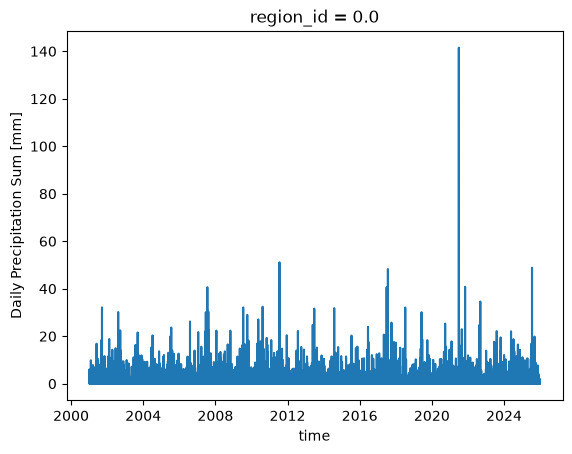

In [47]:
pr_spatial_agg["pr"].sel(region_id=0).plot()

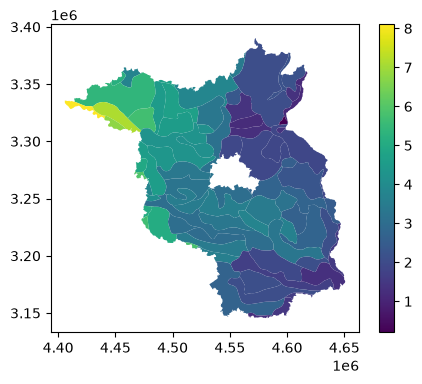

In [49]:
values = (
    pr_spatial_agg["pr"]
    .sel(time="2001-01-01")
    .to_dataframe(name="pr")
    .reset_index()
)

natraum_plot = natraum_3035.merge(
    values,
    on="region_id",
    how="left",
)

natraum_plot.plot(
    column="pr",
    legend=True,
    figsize=(5, 4),
)

plt.show()

In [50]:
sm_top_spatial_agg = xr.open_dataset(Path("../data/processed/sm_dwd_0_10_spatial_agg_natraum_2001_2025.nc"))

In [55]:
summary = sm_top_spatial_agg["sm_dwd_0_10"].groupby("region_id").max(dim="time")

print(summary)

<xarray.DataArray 'sm_dwd_0_10' (region_id: 79)> Size: 632B
array([175.13079866, 191.3979798 , 143.15517241, 183.05526316,
       186.47763158, 193.82105263, 185.11537335, 153.84635762,
       162.15186074, 163.66153846, 165.80842697, 174.51407249,
       163.31909091, 166.57449664, 170.11139601, 177.09275362,
       149.036     , 176.02787724, 184.29706745, 166.21987705,
       187.06945701, 156.35894737, 171.27108434, 172.99677419,
       165.47862745, 182.56484375, 149.52634804, 190.96179775,
       165.08275862, 184.04669951, 204.41      , 187.14224422,
       201.08477509, 151.2981405 , 152.37514124, 175.02065217,
       164.3923913 , 180.4822547 , 174.89238845, 173.12364096,
       161.03823529, 156.39779559, 189.81318681, 231.7       ,
       180.52857143, 166.53203883, 173.8959707 , 187.85936073,
       168.39953917, 162.92865854, 174.01666667, 188.45235405,
       154.04632353, 178.31779141, 186.14893617, 171.79005964,
       161.35223464, 161.36242775, 191.92619048, 164.23629

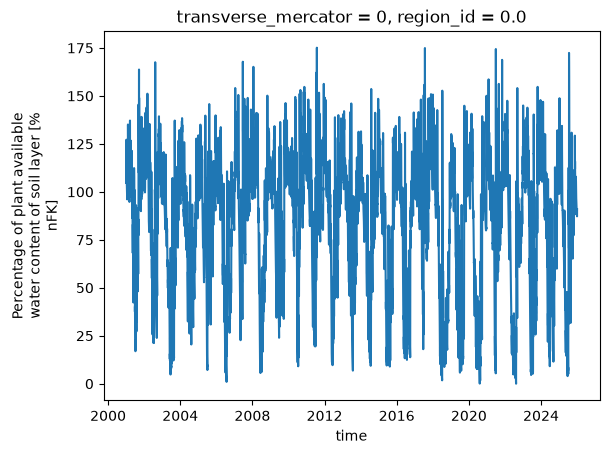

In [51]:
sm_top_spatial_agg["sm_dwd_0_10"].sel(region_id=0).plot()

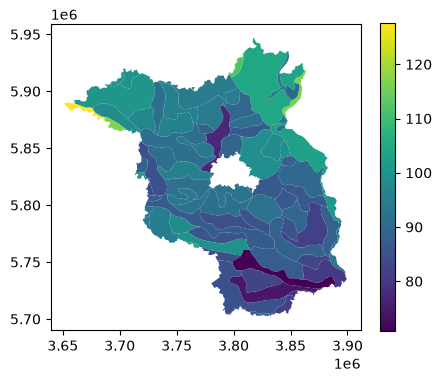

In [52]:
values = (
    sm_top_spatial_agg["sm_dwd_0_10"]
    .sel(time="2001-01-01")
    .to_dataframe(name="sm_dwd_0_10")
    .reset_index()
)

natraum_plot = natraum_31467.merge(
    values,
    on="region_id",
    how="left",
)

natraum_plot.plot(
    column="sm_dwd_0_10",
    legend=True,
    figsize=(5, 4),
)

plt.show()

In [56]:
sm_top_spatial_agg["sm_dwd_0_10"].groupby("region_id").max(dim="time")

<xarray.DataArray 'sm_dwd_0_10' (region_id: 79)> Size: 632B
array([175.13079866, 191.3979798 , 143.15517241, 183.05526316,
       186.47763158, 193.82105263, 185.11537335, 153.84635762,
       162.15186074, 163.66153846, 165.80842697, 174.51407249,
       163.31909091, 166.57449664, 170.11139601, 177.09275362,
       149.036     , 176.02787724, 184.29706745, 166.21987705,
       187.06945701, 156.35894737, 171.27108434, 172.99677419,
       165.47862745, 182.56484375, 149.52634804, 190.96179775,
       165.08275862, 184.04669951, 204.41      , 187.14224422,
       201.08477509, 151.2981405 , 152.37514124, 175.02065217,
       164.3923913 , 180.4822547 , 174.89238845, 173.12364096,
       161.03823529, 156.39779559, 189.81318681, 231.7       ,
       180.52857143, 166.53203883, 173.8959707 , 187.85936073,
       168.39953917, 162.92865854, 174.01666667, 188.45235405,
       154.04632353, 178.31779141, 186.14893617, 171.79005964,
       161.35223464, 161.36242775, 191.92619048, 164.23629032,
       189.60750605, 164.72682927, 166.993     , 161.24      ,
       174.17207207, 165.20552486, 155.59089109, 198.392     ,
       177.72485549, 159.63743119, 152.34952681, 175.36140351,
       171.81829502, 174.2828866 , 174.01943231, 171.78179724,
       179.51818182, 191.15      , 156.86      ])
Coordinates:
  * region_id            (region_id) float64 632B 0.0 1.0 2.0 ... 76.0 77.0 78.0
    transverse_mercator  int64 8B ...
Attributes:
    grid_mapping:    transverse_mercator
    esri_pe_string:  PROJCS["DHDN_3_Degree_Gauss_Zone_3",GEOGCS["GCS_Deutsche...
    standard_name:   percentage_of_plant_available_water_content_of_soil_layer
    units:           % nFK
    long_name:       Percentage of plant available water content of soil layer
    soil_depth:      0-10

In [59]:
sm_top_spatial_agg["sm_dwd_0_10"].quantile([0, 0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999, 1])

<xarray.DataArray 'sm_dwd_0_10' (quantile: 9)> Size: 72B
array([ -4.03602941,   0.97381144,   4.4       ,  11.80721883,
        81.76243094, 120.39905109, 135.02516206, 156.27220279,
       231.7       ])
Coordinates:
  * quantile  (quantile) float64 72B 0.0 0.001 0.01 0.05 0.5 0.95 0.99 0.999 1.0
Attributes:
    grid_mapping:    transverse_mercator
    esri_pe_string:  PROJCS["DHDN_3_Degree_Gauss_Zone_3",GEOGCS["GCS_Deutsche...
    standard_name:   percentage_of_plant_available_water_content_of_soil_layer
    units:           % nFK
    long_name:       Percentage of plant available water content of soil layer
    soil_depth:      0-10

In [ ]:
sm_top_spatial_agg["sm_dwd_0_10"].quantile([0.01, 0.05, 0.5, 0.95, 0.99],dim="time")

<xarray.DataArray 'sm_dwd_0_10' (quantile: 5, region_id: 79)> Size: 3kB
array([[  6.84080823,   7.24474747,  11.9162069 ,   6.16973684,
          3.9875    ,   6.48245614,   5.64455344,   5.70086093,
          6.25889556,   6.40461538,   6.94780899,   6.35031983,
          5.40809091,   5.16966443,   3.96364672,   5.5647205 ,
          4.64232   ,   4.58664962,   5.68645161,   5.31454918,
          5.64479638,   5.03989474,   6.47879518,   3.41806452,
          7.83972549,   4.64433594,   4.06724265,   4.55898876,
          5.14551724,   5.54962562,   4.07708696,   4.5039934 ,
          5.27778547,   4.13192149,   6.52002825,   3.97815217,
          5.71597826,   4.41906054,   3.92120735,   3.89068268,
          3.32323529,   6.4143487 ,   4.3217033 ,   1.8       ,
          2.83404762,   4.84271845,   5.1724359 ,   3.27917808,
          4.89198157,   6.3795122 ,   3.55037037,   3.79634652,
          4.02066176,   4.55404908,   3.75021277,   4.87882704,
          4.54178771,   4.45491329,   3.41607143,   4.38346774,
          4.26871671,   4.53487805,   5.19255   ,   7.04969231,
          3.72396396,   4.84577348,   3.62221782,   2.5132    ,
          4.60479769,   4.07533945,   2.99362776,   3.83567251,
          3.90492337,   3.62270103,   3.64727074,   3.08156682,
          2.31636364,   3.30863636,   2.60925   ],
...
       [141.87774749, 157.13848485, 121.2912069 , 142.36986842,
        140.74684211, 148.04280702, 143.27407028, 137.84980132,
        127.35973589, 129.12346154, 130.30154494, 134.26249467,
        122.58263636, 127.74536913, 128.19811966, 136.21517598,
        142.13456   , 133.93173913, 142.92404692, 119.12497951,
        139.62076923, 141.66368421, 125.57831325, 132.07741935,
        125.87208824, 126.22195313, 136.1133701 , 130.56696629,
        124.42655172, 134.32628571, 138.93591304, 130.43663366,
        136.75103806, 124.23541322, 124.70771186, 135.7823913 ,
        123.25532609, 131.90235908, 130.72173228, 134.35142857,
        138.06205882, 123.04088176, 133.22335165, 151.34      ,
        132.75928571, 130.46640777, 129.18194139, 136.24369863,
        127.84654378, 122.71381098, 128.69462963, 132.74638418,
        133.64639706, 138.14107362, 137.07234043, 132.72192843,
        124.23113128, 128.71043353, 131.08353175, 133.955     ,
        127.73743341, 131.71682927, 129.8883    , 126.38878462,
        136.56459459, 122.45983425, 130.06841584, 148.5116    ,
        127.80716763, 125.6852844 , 113.44247634, 130.88608187,
        128.90045019, 127.71290722, 127.38709607, 121.420553  ,
        130.62454545, 132.096     , 125.65425   ]])
Coordinates:
  * quantile   (quantile) float64 40B 0.01 0.05 0.5 0.95 0.99
  * region_id  (region_id) float64 632B 0.0 1.0 2.0 3.0 ... 75.0 76.0 77.0 78.0
Attributes:
    grid_mapping:    transverse_mercator
    esri_pe_string:  PROJCS["DHDN_3_Degree_Gauss_Zone_3",GEOGCS["GCS_Deutsche...
    standard_name:   percentage_of_plant_available_water_content_of_soil_layer
    units:           % nFK
    long_name:       Percentage of plant available water content of soil layer
    soil_depth:      0-10

# Temporal Aggregation

In [61]:
pr_spatial_agg = xr.open_dataarray("../data/processed/pr_spatial_agg_natraum_2001_2025.nc")
pr_spatial_agg

<xarray.DataArray 'pr' (time: 9131, region_id: 79)> Size: 3MB
[721349 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 73kB 2001-01-01 2001-01-02 ... 2025-12-31
  * region_id  (region_id) float64 632B 0.0 1.0 2.0 3.0 ... 75.0 76.0 77.0 78.0
Attributes:
    standard_name:      thickness_of_rainfall_amount
    long_name:          Daily Precipitation Sum
    units:              mm
    CoordinateSystems:  LatLonCoordinateSystem ProjectionCoordinateSystem
    esri_pe_string:     PROJCS["ETRS_1989_LAEA",GEOGCS["GCS_ETRS_1989",DATUM[...
    grid_mapping:       crs
    cell_methods:       time: sum

In [64]:
# construct calender-dekads and group by the triple of year, month, dekad 
dates = pd.DatetimeIndex(pr_spatial_agg.time.values)

dekad_of_month = np.where(dates.day <= 10, 1,
                          np.where(dates.day <= 20, 2, 3)
                          )

pr_spatial_agg = pr_spatial_agg.assign_coords(
    year=("time", dates.year),
    month=("time", dates.month),
    dekad=("time", dekad_of_month),
)

pr_spatial_agg_dekadal = pr_spatial_agg.groupby(["year", "month", "dekad"]).sum(dim="time")


In [66]:
pr_spatial_agg_dekadal.shape

(79, 25, 12, 3)

In [ ]:
sm_spatial_agg = xr.open_dataarray("../data/processed/pr_spatial_agg_natraum_2001_2025.nc")
pr_spatial_agg

# Dekad Anomalies